All configuration and model checks passed.
Layer depths = [   0.   30.  120.  300. 1000. 5000.]
Number of points per layer along Z = [ 3  6  3 11 56]
Spacing in each layer in meters = [10.54852321 15.13199041 52.74261603 63.29113924 70.88607595 79.11392405]
Qseis Inputs cleaned, parent folder intact.
Creating all input files ...
All input files created!
Prepared 471 total runs
Cores available: 64
Preparing to run 471 QSEIS jobs with 64 worker(s)...


/home/koley/.conda/envs/pySeis1DNN/lib/python3.11/site-packages/pysurf96/wrapper.py:99: RuntimeWarning: overflow encountered in cast
  error = surfdisp96(


[Worker 713891] Starting job Layer0Run0 at 17:23:55[Worker 713892] Starting job Layer0Run1 at 17:23:55[Worker 713894] Starting job Layer0Run3 at 17:23:55[Worker 713895] Starting job Layer0Run4 at 17:23:55[Worker 713893] Starting job Layer0Run2 at 17:23:55[Worker 713896] Starting job Layer0Run5 at 17:23:55[Worker 713897] Starting job Layer0Run6 at 17:23:55[Worker 713899] Starting job Layer0Run8 at 17:23:55[Worker 713898] Starting job Layer0Run7 at 17:23:55[Worker 713900] Starting job Layer0Run9 at 17:23:55[Worker 713902] Starting job Layer0Run11 at 17:23:55[Worker 713903] Starting job Layer0Run12 at 17:23:55[Worker 713901] Starting job Layer0Run10 at 17:23:55[Worker 713904] Starting job Layer0Run13 at 17:23:55
[Worker 713905] Starting job Layer0Run14 at 17:23:55[Worker 713906] Starting job Layer0Run15 at 17:23:55

[Worker 713907] Starting job Layer0Run16 at 17:23:55





[Worker 713908] Starting job Layer0Run17 at 17:23:55


[Worker 713909] Starting job Layer0Run18 at 17:23:55

[Worker 

/home/koley/pySeisNN1DFull/modules/NNCompute.py:1136: RuntimeWarning: invalid value encountered in sqrt
  qP = (2*np.pi*freqs)/(vR*vP[0])*np.sqrt(vP[0]**2 - vR**2)
/home/koley/pySeisNN1DFull/modules/NNCompute.py:1137: RuntimeWarning: invalid value encountered in sqrt
  qS = (2*np.pi*freqs)/(vR*vS[0])*np.sqrt(vS[0]**2 - vR**2)


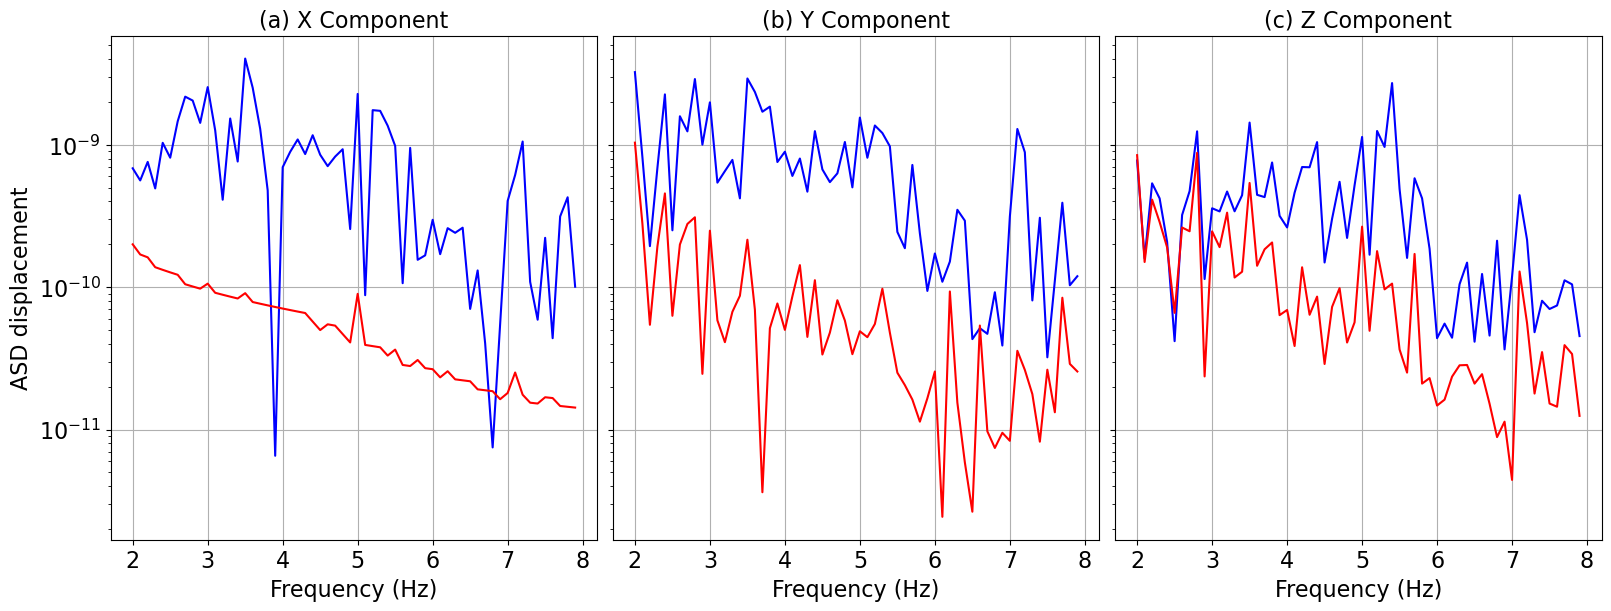

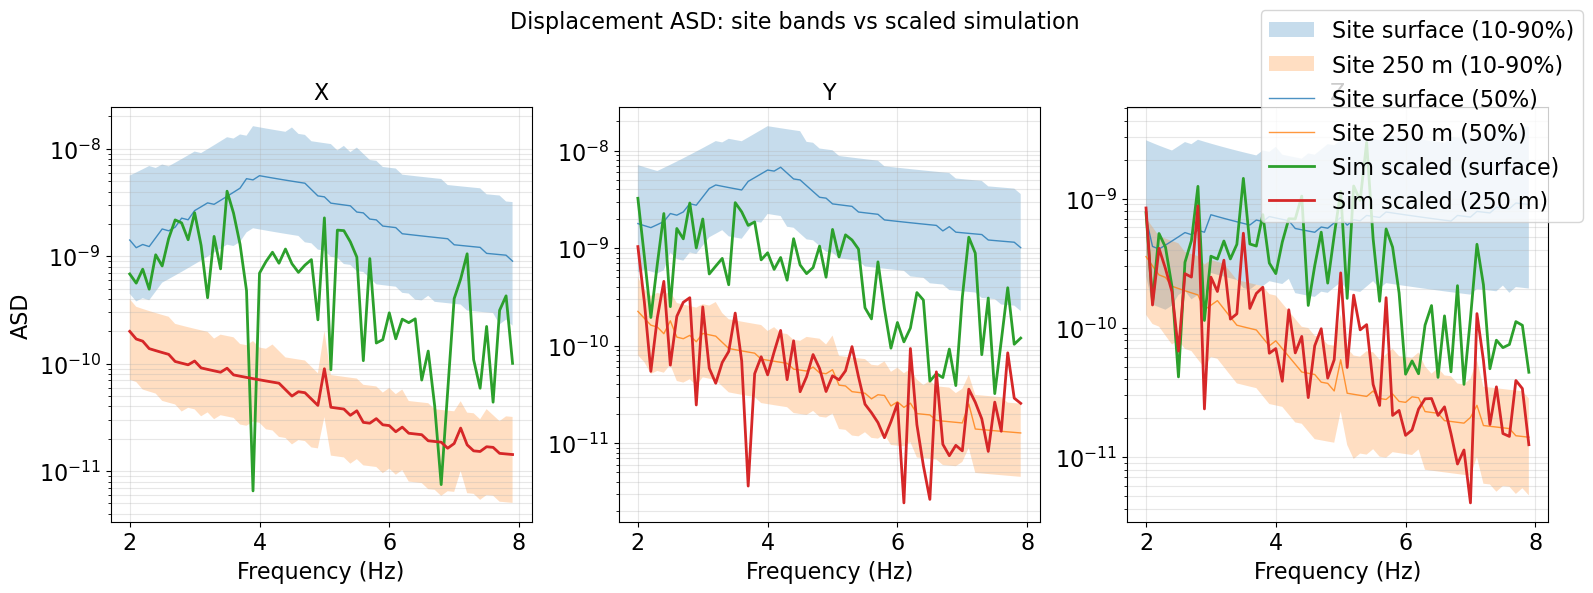

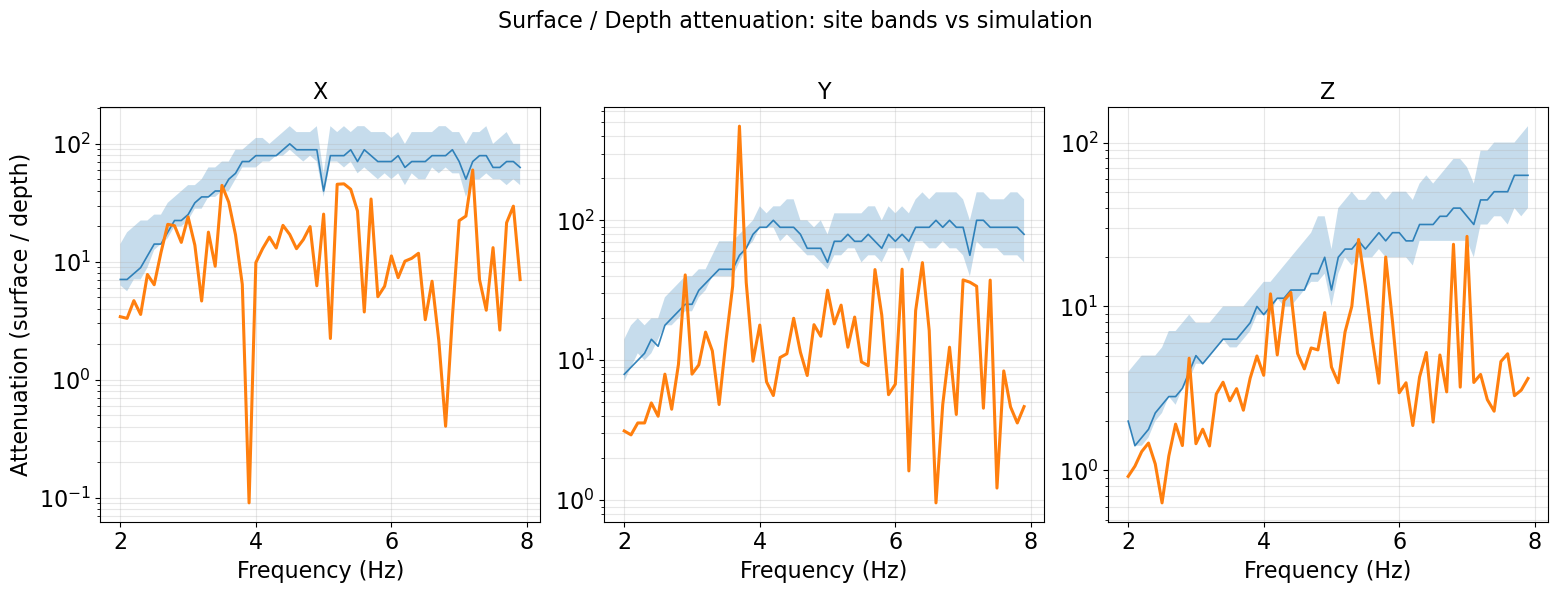

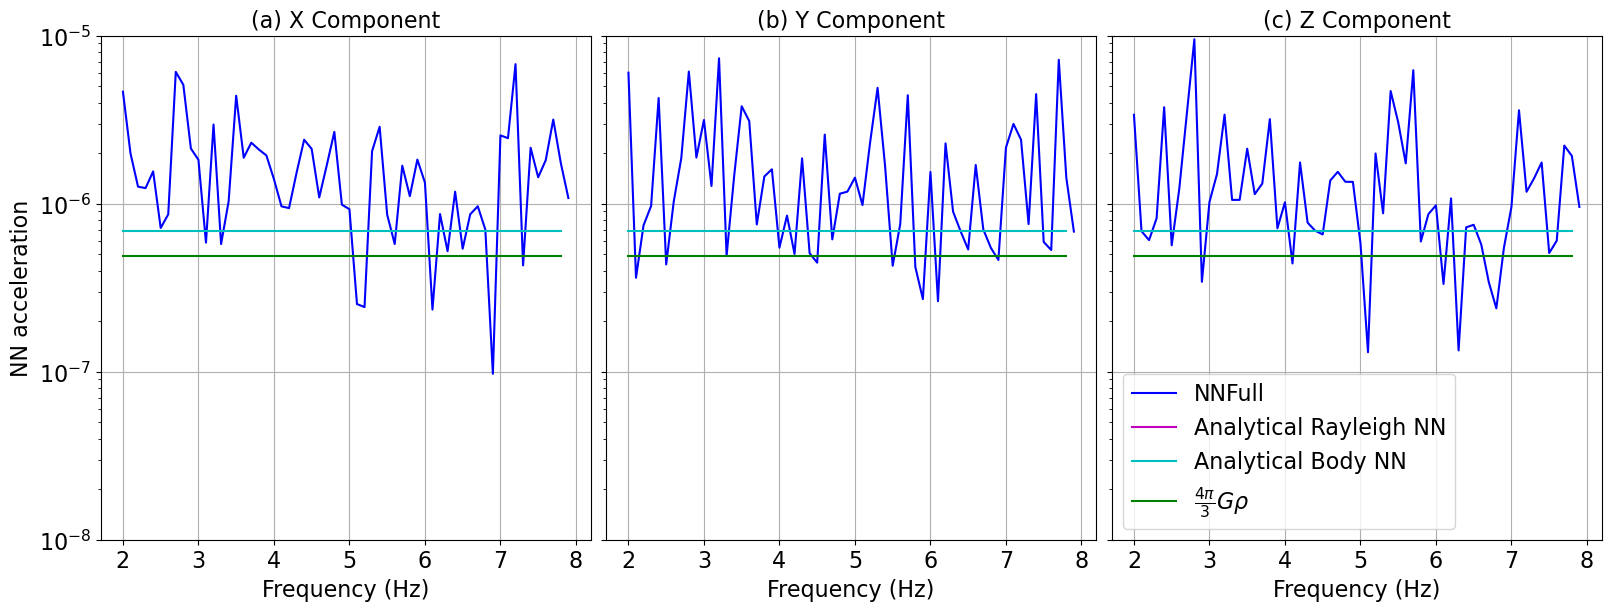

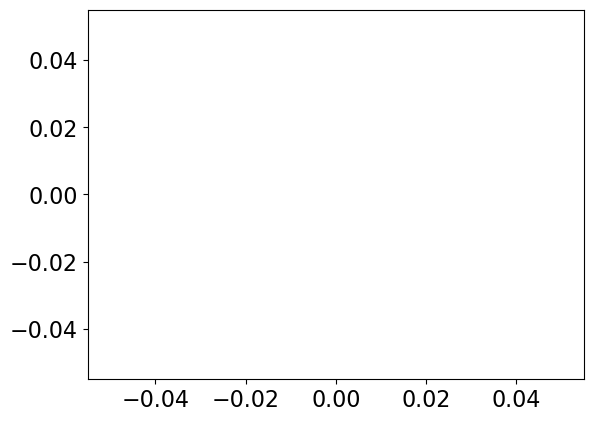

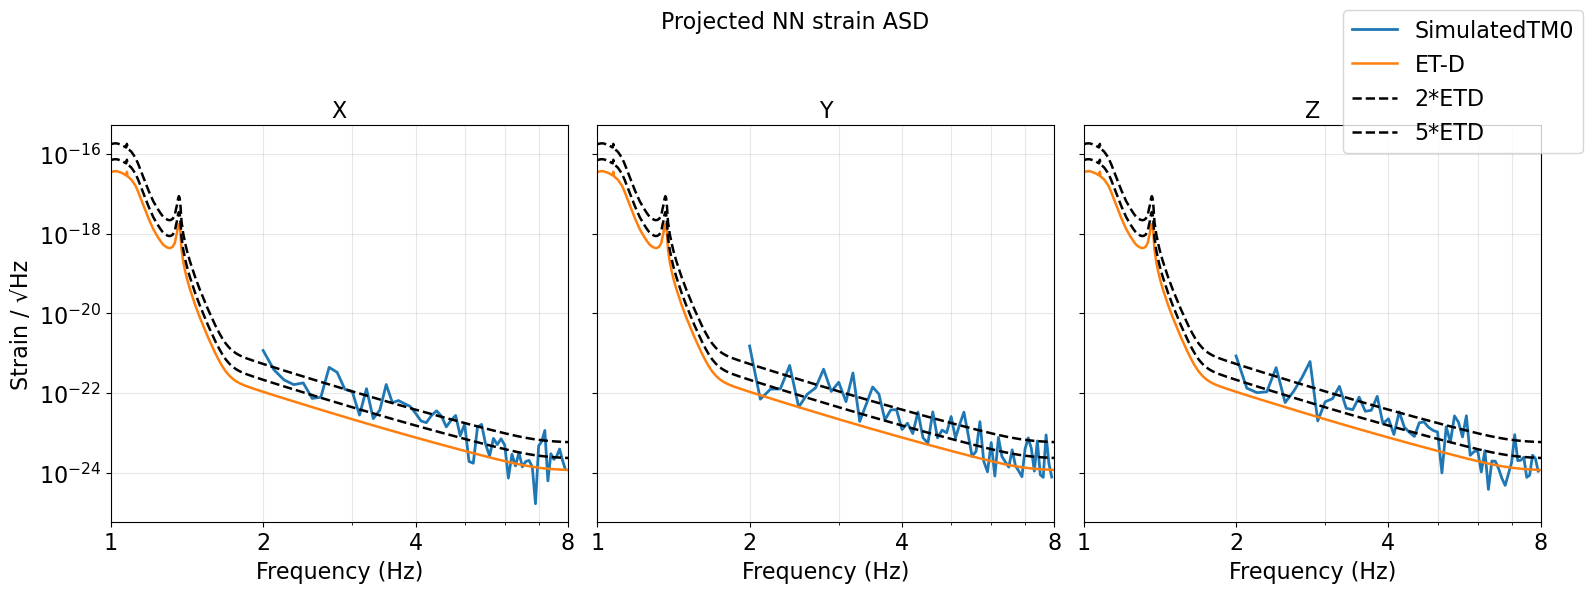

In [ ]:
# script for computing NN for a layered model
# the sources are distributed on the surface and in rings
# based on the optimization weights obtained in optAttnWeights.ipynb
# the vertical and the horizontal forces are assigned weights separately for every frequency
# for check we will just do one realization 
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.io import loadmat
import scipy.constants as const

from pysurf96 import surf96
from modules import configLoader
from modules import validateInputs
from modules import createDB
from modules import NNGeometryNN
from modules import gfLoader
from modules import simDisp
from modules import NNCompute
from modules import NNPP
from modules import plotUtils

def main():

    # load the config file, point to the layered config with weights
    configFile="/home/koley/CavityResults/SphFullRunRingWtsConfig/configParseFullFieldLayerRingWts.ini"
    config = configLoader.load_config(configFile)
    # load all cavities
    allCavities = configLoader.loadCavities('/home/koley/CavityResults/SphFullRunRingWtsConfig/SingleSphCavity.ini')
    validateInputs.validateInputs(config)
    # specify the path where the optmized weights were saved
    dispSavePath = '/home/koley/CavityResults/AllTutOut/AttnKernel/'

    # load the ring weights
    wtReg = loadmat(os.path.join(dispSavePath, "opt_HV_ringWeights.mat"))
    weightsReg = wtReg['weightsReg']
    qVReg = wtReg['qVReg']
    qHReg = wtReg['qHReg']
    
    # specify the ring bounds used during the optimization
    ringBounds = np.array([[100.0,  200.0],[200.0,  500.0],[500.0, 1000.0],[1000.0, 2000.0],
                            [2000.0, 3000.0],[3000.0, 4000.0],[4000.0, 5000.0],[5000.0, 6000.0]])
    nRing = len(ringBounds)
    
    fullSpace = False
    splitAll = createDB.createFinalInputs(config)
    
    print(f"Prepared {splitAll.shape[0]} total runs")
    print(f"Cores available: {config.cpuCoresQseis}")
    
    results = createDB.runMultiQseis(splitAll, config.inputPath, config.qseisExe, nWorkers = config.cpuCoresQseis)
        
    print("Database generation complete")
        
    # flag for pure Rayleigh wavefield in homogeneous half-space
    ifRay = config.ifRay

    # flag for plane P and S waves in homogeneous half space
    ifBody = config.ifBody

    # flag for wavefield simulation
    ifFullField = config.ifFullField

    saveHV = config.saveHV

    thickness = config.thickness # units in meters
    vs = config.vS # units in m/s
    vp = config.vP # units in m/s
    rho = config.rho # units in kg/m^3
    rhoAir = config.rhoAir # density of air
    fMin = config.fMin; fMax = config.fMax; df = config.df;# units in Hz
    lambdaFrac = config.lambdaFrac # fraction
    lambdaRes = config.lambdaRes; #must be greater than 4
    
    # given a cuboidal domain should be greater than sqrt of 
    xMaxGF = config.xMaxGF # maximum horizontal offset upto which displacements will be used
    zMaxGF = config.zMaxGF # maximum depth upto which displacements will be used
    maxRec = config.maxRec # same value of number of receivers that qseis can handle in one go check qsglobal.h
    xCenter = config.xCenter; yCenter = config.yCenter
    xMin = xCenter-config.xExtent; xMax = xCenter+config.xExtent # minimum and maximum of the simulation domain in X-direction (EW)
    yMin = yCenter-config.yExtent; yMax = yCenter+config.yExtent # maximum and minimum of the simulation domain in Y-direction (NS)
    zMin = 0.0; zMax = config.zExtent # maximum and minimum of the simulation domain in Z-direction (depth)

    # check if the GFs are generated up to correct hoizontal offsets
    xDiag = (xMax-xMin)*np.sqrt(2); yDiag = (yMax-yMin)*np.sqrt(2);
    if(xMaxGF<xDiag or xMaxGF<yDiag):
        raise ValueError("xMaxGF must be >= sqrt(2)x(xMax-xMin) and sqrt(2)x(yMax-yMin)")

    if(zMaxGF<zMax):
        raise ValueError("zMaxGF must be greater >= zMax")
        
    domXYBounds = (xMin,xMax,yMin,yMax)

    # specify test-mass locations, this was originally defined after cubeTop cubeBot definition
    itmAC = config.itmAC; itmAB = config.itmAB; etmCA = config.etmCA; etmBA = config.etmBA
        
    print('itmAC = ' + str(itmAC[0]) + ', ' + str(itmAC[1]) + ', ' + str(itmAC[2]))
    # make itmAC[2] negative, because in the configfile it is positive
    itmACUse = itmAC.copy(); itmACUse[2] = -np.abs(itmACUse[2])
    itmABUse = itmAB.copy(); itmABUse[2] = -np.abs(itmABUse[2])
    etmCAUse = etmCA.copy(); etmCAUse[2] = -np.abs(etmCAUse[2])
    etmBAUse = etmBA.copy(); etmBAUse[2] = -np.abs(etmBAUse[2])
        
    itmAll = np.vstack((itmACUse,))
    nTM = len(itmAll[:,0])
    G = const.G
    
    # an addition from the older version, where it is impoprtant to note that which cavity hosts
    # which test-mass
    
    tmInCavity = NNGeometryNN.findTMInCavity(allCavities, itmAll)
    
    # generate the grid size required
    gridSize = NNCompute.getGridSize(thickness,vp, vs, rho, fMin, fMax, lambdaFrac, lambdaRes)
    print('grid size in each layer before partitioning = ' + str(gridSize))
    
    # get the background gridsize in the layer hosting the cavities
    hBGAll = NNGeometryNN.getHBG(thickness,allCavities,gridSize)
    etaUse = 1.0
    radNow = allCavities[0]['radius']
    # now get the refinement extent for all cavities
    wallRefineWidthAll = NNGeometryNN.getRefineWidths(tmInCavity, allCavities, hBGAll,eta=etaUse,
                                                minRefine=20.0,)
    print('wallRefineWidth = ')
    print(wallRefineWidthAll)
        
    refineBoxes = NNGeometryNN.makeRefineBoxesFromCavities(allCavities,wallRefineWidthAll,domainZBounds=(zMin,zMax))
    
    cubeTopAll = np.zeros((len(allCavities),))
    cubeBotAll = np.zeros((len(allCavities),))
    for boxNo, box in enumerate(refineBoxes):
        cubeTopAll[boxNo] = box.zMin
        cubeBotAll[boxNo] = box.zMax
    cubeTop = min(cubeTopAll)
    cubeBot = max(cubeBotAll)
    # new part added
    cavDepthAll = np.zeros((len(allCavities),))
    for cavNo, cav in enumerate(allCavities):    
        if(cav["shape"]=="cuboid"):
            cavDepthAll[cavNo] = cav["zC"]
        elif(cav["shape"] == 'sphere'):
            cavDepthAll[cavNo] = cav["zC"]
        else:
            raise ValueError('Unsupported cavity type')
    cavDepthUse = min(cavDepthAll)
    
    print("CubeTop = " + str(cubeTop) +  'CubeBot = ' + str(cubeBot))
    
    # some other inputs for simDisp
    maxRec = config.maxRec; # same value of number of receivers that qseis can handle in one go check qsglobal.h
    tMax = config.tMax; nSamp = config.nSamp
    
    # specify the folder where you want to write all input files, should have rw access
    # fInpPath is the path where the Green's function database exists
    fInpPath = config.inputPath #like "/data/gravwav/koley/QseisInpN/"
    #fInpPath = "/data/gravwav/koley/SALVUSOut/"

    # outDispPath should have rw access and is used for saving temp displacementy files
    outDispPath = config.outDispPath # like "/data/gravwav/koley/OutDisp/"

    # saves the NN and displacement values per realization
    outDispRea = config.outDispPathRea # like "/data/gravwav/koley/OutDispRea/"
    
    # GF components to be used
    components = ['fh-2.tz', 'fh-2.tr', 'fh-2.tt', 'fz-2.tz', 'fz-2.tr']

    # splitAll is necessary so load it
    nRea = config.nRea # number of realizations

    # this file is created at the time of database generation
    splitFileName = fInpPath + 'splitAll.mat'
    splitMat = loadmat(splitFileName)
    splitAll = splitMat['splitAll']

    # source distribution parameters
    R1 = config.R1; R2 = config.R2
    nSrc = config.nSrc
    srcDistri = config.srcDistri
    scaleVH = config.scaleVH
    # flag if NN is computed directly without writing the displacemnet field
    onFlyNN = config.onFlyNN 

    # number of CPUs to be used for displacement and NN simulation
    nCPUDisp = config.cpuCoresDisp
    nCPUNN = config.cpuCoresNN
    computeStrategy = config.computeStrategy

    # frequency axis to be used by simDisp
    freqOut, idxFreq, df_native = simDisp.getFreqGrid(tMax, nSamp, fMin, fMax, df)
    nFreq = len(freqOut)

    splitAllNew = gfLoader.assembleQseisRuns(splitAll, fInpPath, components, outPath=None, fIndices=idxFreq, onlySplitAll = False, minVel=100.0)
    #splitAllNew = np.load(os.path.join(fInpPath,'splitAllNew.npy'))
         
    # in case only Rayleigh waves in homogeneous half space is used, Rayleigh wave phase velocity is needed
    if(ifRay):
        periods = 1/freqOut
        vR = surf96(thickness,vp,vs,rho,periods,wave="rayleigh",mode=1,velocity="phase",flat_earth=True)
    else:
        vR = None
    # two depth points for scaling, displacement saved per realization
    zList = [0.0,cavDepthUse]
    
    # generate the grid size required
    gridSize = NNCompute.getGridSize(thickness,vp, vs, rho, fMin, fMax, lambdaFrac, lambdaRes)
    
    print('grid size in each layer before partitioning = ' + str(gridSize))
    
    # create the layers and partition
    layers, vp2, vs2, rho2, gridSize2 = NNGeometryNN.createAllLayers(xMin, xMax, yMin, yMax, thickness,
                                                                     zMax,vp,vs,rho,gridSize,cubeTop,cubeBot)
    print('New gridSize after partioning = '+ str(gridSize2))

    print('Total number of layers = ' + str(len(layers)))
    nLayers = len(layers)
    
    for reaNo in range(0,nRea):
        print('Doing realization = ' +str(reaNo))
        # get the source distribution per realization
        # assign weights to the sources in each ring based on the optimized weights
        xSrcAll = [];ySrcAll = [];azSrcAll = [];phiHAll = [];ampHAll = [];phiVAll = [];ampVAll = []
        for iRing, (R1, R2) in enumerate(ringBounds):
            xSrc, ySrc, azSrc, srcMeta = simDisp.genAmbSrc(nSrc,mode=srcDistri,R1=R1,R2=R2,randomPhase=True,
                                                           freqDependent=True,nFreq=nFreq,decoupledHV=config.decoupledHV,
                                                           scaleVH=scaleVH)
        
            # fitted power weight for this ring
            # weightsReg has shape (nFreq, nRing)
            wRing = weightsReg[:, iRing]
        
            # convert power weight -> amplitude weight
            ampScaleV = np.sqrt(100/nSrc)*np.sqrt(qVReg[:, iRing])
            ampScaleH = np.sqrt(100/nSrc)*np.sqrt(qHReg[:, iRing])
            # apply to every source in this ring
            srcMeta["ampH"] *= ampScaleH
            srcMeta["ampV"] *= ampScaleV
        
            xSrcAll.append(xSrc)
            ySrcAll.append(ySrc)
            azSrcAll.append(azSrc)
        
            phiHAll.append(srcMeta["phiH"])
            ampHAll.append(srcMeta["ampH"])
        
            phiVAll.append(srcMeta["phiV"])
            ampVAll.append(srcMeta["ampV"])
        
        xSrc = np.concatenate(xSrcAll)
        ySrc = np.concatenate(ySrcAll)
        azSrc = np.concatenate(azSrcAll)
        
        srcMeta = {"phiH": np.concatenate(phiHAll, axis=0),"ampH": np.concatenate(ampHAll, axis=0),
                           "phiV": np.concatenate(phiVAll, axis=0),"ampV": np.concatenate(ampVAll, axis=0)}
        # in case the body wave in homogeneous half-space flag is turned on
        if(ifBody):
            metaBody = simDisp.genBodySrc(nSrc, nFreq, eP = 1/3, eS = 2/3)
            
        else:
            metaBody=None
        
        # create and save the displacement field on surface and depth for scaling afterwards
        if(ifRay):
            # uses ambient Rayleigh wavefield in homogeneous half space
            phiSrc = srcMeta["phiV"]; ampSrc = srcMeta["ampV"]
            simDisp.getSurfDeepRayDispPerRea(zList, azSrc, phiSrc, ampSrc, outDispRea, reaNo, vR,
                                             vp2[0], vs2[0], freqOut=freqOut)
            # save the source parameters for reproducibility
            raySrcFileName = os.path.join(outDispRea,f"RaySrcRea{reaNo}.npz")
            np.savez_compressed(raySrcFileName,phiSrc=phiSrc,ampSrc=ampSrc,azSrc=azSrc)

        elif(ifBody):
            # uses Plane P and S wave in homogeneous half space
            simDisp.getSurfDeepBodyDispPerRea(zList, metaBody, outDispRea, reaNo, vp2[0], vs2[0], freqOut=freqOut)
            bodySrcFileName = os.path.join(outDispRea,f"BodySrcRea{reaNo}.npz")
            # save the body wave source parameters for reproducibility
            np.savez_compressed(bodySrcFileName,metaBody=metaBody)
        else:
            # uses QSEIS full wavefield simulation instead
            simDisp.getSurfDeepDispPerRea(zList, xSrc, ySrc, azSrc, srcMeta, xMaxGF, splitAll, fMin, fMax, outDispRea,
                    fInpPath, components, reaNo, idxFreq = idxFreq, freqOut=freqOut)
            ffSrcFileName = os.path.join(outDispRea,f"FullFieldSrcRea{reaNo}.npz")
            # save the source parameters for reproducibility
            np.savez_compressed(ffSrcFileName,xSrc=xSrc, ySrc=ySrc, azSrc=azSrc, srcMeta=srcMeta)
        
        # preallocate per realization
        IBlockTot = np.zeros((nFreq,3,nTM),dtype=np.complex128)
        IVertFaceTot  = np.zeros((nFreq,3,nTM),dtype=np.complex128)
        IHorFaceTot = np.zeros((nFreq,3,nTM),dtype=np.complex128)
        ITot = np.zeros((nFreq,3,nTM),dtype=np.complex128)
        
        for layerNo, layer in enumerate(layers):
            layer = layers[layerNo]

            # need to redefine cubeTop and cubeBot for multiple cavities
            layer.updateCubeInteraction(cubeTop, cubeBot)
            #layer.generateBlocks(xMin, xMax, yMin, yMax, cubeC, ax, ay, az, domXYBounds)
            layer.generateBlocksNew(refineBoxes=refineBoxes,domXYBounds=domXYBounds,
                                    domainZBounds=(zMin, zMax))
            
            print(layer)
            blkNo = 1
            for blk in layer.blocks:
                print(blk);
                print('Block = '+str(blkNo))
                print('Integrating volume  NN block in layer' + str(layerNo))

                # new version signature
                IBlock = NNCompute.runVolNNComputeBlock(blk, gridSize2[layerNo], freqOut, allCavities, itmAll,
                                                        xSrc, ySrc, azSrc,srcMeta, idxFreq, fMin, fMax, outDispPath, splitAll, xMaxGF,
                                                        fInpPath, components, vR, useSimDisp=ifFullField, ifRay = ifRay, ifBody = ifBody,
                                                        nCPUDisp=nCPUDisp, nCPUNN=nCPUNN, nChunk=20000,metaBody=metaBody,
                                                        computeStrategy=computeStrategy,saveHV=saveHV)
                # new version
                IBlockTot = IBlockTot + IBlock

                # now compute the surface NN from the vertical faces of the block which form the outer boundary
                for f in blk.verticalFaces:
                    if(f.isBoundary):
                        print('Integrating vertical surface NN block in layer' + str(layerNo))
                        print('vertical boundary face found')
                        # is an outer boundary
                        IVertFace = NNCompute.runVertSurfNNCompute(f, gridSize2[layerNo], freqOut, itmAll, xSrc, ySrc, azSrc,
                                                         srcMeta, idxFreq, fMin, fMax, outDispPath, splitAllNew,
                                                         xMaxGF, fInpPath, components, vR, nCPUDisp=1, nChunk = 20000, 
                                                         useSimDisp=ifFullField, ifRay = ifRay, ifBody = ifBody, vP_for_test=blk.vP,
                                                         vS_for_test=blk.vS, metaBody=metaBody,
                                                         computeStrategy=computeStrategy,saveHV=saveHV, reduceNN=onFlyNN)
                        
                        IVertFaceTot = IVertFaceTot + IVertFace
        
                
                # now compute the surface NN from the horizontal interfaces at the very end of layers
                print('Integrating horizontal surface NN block in layer' + str(layerNo))
                IHorFace = NNCompute.handleHorSurfNN(layer, layers, blk, gridSize2[layerNo], nLayers, layerNo, rhoAir, freqOut, 
                                           allCavities, itmAll, xSrc, ySrc, azSrc, srcMeta, idxFreq, fMin, fMax, outDispPath,
                                           splitAllNew, xMaxGF, fInpPath, components, vR, nCPUDisp=nCPUDisp,
                                           nCPUNN=nCPUNN, useSimDisp = ifFullField, ifRay = ifRay, ifBody = ifBody,
                                           vP_for_test=blk.vP, vS_for_test = blk.vS, metaBody = metaBody, chunk_size=20000,
                                           computeStrategy=computeStrategy, saveHV=saveHV, reduceNN=onFlyNN, fullSpace=fullSpace)
                                
                IHorFaceTot = IHorFaceTot + IHorFace
                
                blkNo = blkNo+1
    
        IVertFaceTot = IVertFaceTot*G
        IHorFaceTot = IHorFaceTot*G
        IBlockTot = IBlockTot*G
        ITot = (IBlockTot-IVertFaceTot-IHorFaceTot)
        # save the NN per realization
        nnFName = 'NNFullRea' + str(reaNo) + '.npz'
        np.savez(os.path.join(outDispRea, nnFName), IVertFaceTot = IVertFaceTot, IHorFaceTot = IHorFaceTot,
                 IBlockTot = IBlockTot, ITot = ITot, freqOut=freqOut)

    dispPointAllRea, attnAllRea, freqDisp = simDisp.assembleSurfDeepDispAllRea(outDispRea, zList, freqOut, nRea)
    nnAllRea, nnVolAllRea, nnSurfAllRea, fNN = NNCompute.assembleNNAllReaAllTM(outDispRea,freqOut, nRea,nTM)

    # preparing for output visualization
    plotUtils.set_plot_style(style='medium')
    
    ################################################################################################
    # scaling the surface and deep displacements
    scaledSimDisp, asdSurfX, asdSurfY, asdSurfZ, asdBHX, asdBHY, asdBHZ = NNPP.scaleDisp(
        dispPointAllRea, freqOut, config, scaleComp='E', scaleDepth = 'depth', scaleToTrue=True)
    # make plot
    figDisp, axDisp = plotUtils.plotPSDDeepSurfMulti(freqOut, scaledSimDisp[:,:,0], '0 m deep', 'b', fig=None, axs=None, 
                                         quantity="ASD displacement")
    figDisp, axDisp = plotUtils.plotPSDDeepSurfMulti(freqOut, scaledSimDisp[:,:,1], '250 m deep', 'r', fig=figDisp, axs=axDisp, 
                                         quantity="ASD displacement")
    # compare the scaled simulated displacements to those observed at site
    figSh, axSh = plotUtils.plotScaledVsSiteASD(freqOut, scaledSimDisp, asdSurfX, asdSurfY, asdSurfZ,
                                                asdBHX, asdBHY, asdBHZ)
    ################################################################################################

    # compare simulated and site based attenuation between surface and depth
    attnSim, attnX, attnY, attnZ = NNPP.getAttn(dispPointAllRea,freqOut,config)
    figAttn, axAttn = plotUtils.plotAttn(freqOut, attnSim, attnX, attnY, attnZ)
    
    ################################################################################################
    # scale the simulated Newtonian acceleration such that displacement is set to 1
    scaledNN = np.zeros((nFreq,3,nTM))
    for i in range(0,nTM):
        scaledNN[:,:,i], *__ = NNPP.scaleNN(nnAllRea[:,:,i], dispPointAllRea, freqOut, config, scaleComp="E", scaleDepth="depth",
                                 scaleToTrue=False)
    # plot the scaleNN
    colTM = ['b','g','r','y']
    for i in range(0,nTM):
        if(i==0):
            figNN, axNN = plotUtils.plotPSDDeepSurfMulti(fNN, scaledNN[:,:,i], 'NNFull', colTM[i], fig=None, axs=None,
                                                         quantity="NN acceleration")
        else:
            figNN, axNN = plotUtils.plotPSDDeepSurfMulti(fNN, scaledNN[:,:,i], 'NNFull', colTM[i], fig=figNN, axs=axNN, 
                                                                      quantity="NN acceleration")
    
    NNRay,freqNNRay = NNCompute.getAnalyticRayNN(config, cavDepthUse)
    figRay, axRay = plt.subplots()
    axRay.plot(freqNNRay,NNRay)
    
    NNBody, minNN, freqNNBody = NNCompute.getAnalyticBodyNN(config,p=1/3)

    axNN[0].plot(freqNNRay, NNRay,'m',label='Analytical Rayleigh NN')
    axNN[1].plot(freqNNRay, NNRay,'m',label='Analytical Rayleigh NN')
    axNN[2].plot(freqNNRay, NNRay,'m',label='Analytical Rayleigh NN')

    axNN[0].plot(freqNNBody, NNBody,'c',label='Analytical Body NN')
    axNN[1].plot(freqNNBody, NNBody,'c',label='Analytical Body NN')
    axNN[2].plot(freqNNBody, NNBody,'c',label='Analytical Body NN')

    axNN[0].plot(freqNNBody, minNN,'g',label=r'$\frac{4\pi}{3} G \rho$')
    axNN[1].plot(freqNNBody, minNN,'g',label=r'$\frac{4\pi}{3} G \rho$')
    axNN[2].plot(freqNNBody, minNN,'g',label=r'$\frac{4\pi}{3} G \rho$')

    #axNN[0].legend()
    #axNN[1].legend()
    axNN[2].legend()

    axNN[0].set_ylim(10**-7,2*10**-6)
    axNN[1].set_ylim(10**-8,10**-5)
    axNN[2].set_ylim(10**-8,10**-5)

    ################################################################################################
    # compute scaleNN when the simulated displacement is scaled to match site ASD
    scaledNNToTrue = np.zeros((nFreq,3,nTM))
    nnProj = np.zeros((nFreq,3,nTM))
    for i in range(0,nTM):
        scaledNNToTrue[:,:,i], *__ = NNPP.scaleNN(nnAllRea[:,:,i], dispPointAllRea, freqOut, config, scaleComp="E",
                                       scaleDepth="depth", scaleToTrue=True)
        nnProj[:,:,i], ETD = NNPP.NNProjectToET(scaledNNToTrue[:,:,i], fNN, config)

    for i in range(0,nTM):
        if(i==0):
            figSens, axSens = plotUtils.plotNNStrainET(fNN, nnProj[:,:,i], ETD, title="Projected NN strain ASD", xlim=(1, 8), xscale="log",
                        yscale="log", comp_labels=("X", "Y", "Z"), sim_label="SimulatedTM"+str(i), etd_label="ET-D",
                        legend_once=True, fig=None,axs=None)
        else:
            figSens, axSens = plotUtils.plotNNStrainET(fNN, nnProj[:,:,i], ETD, title="Projected NN strain ASD", xlim=(1, 8), xscale="log",
                        yscale="log", comp_labels=("X", "Y", "Z"), sim_label="SimulatedTM" + str(i), etd_label="ET-D",
                        legend_once=True, fig=figSens,axs=axSens)

if __name__ == "__main__":
    main()